# ĐỒ ÁN CS114 — DỰ ĐOÁN SỰ HÀI LÒNG CỦA HÀNH KHÁCH HÀNG KHÔNG


| Nội dung | Cách làm |
|---|---|
| Dữ liệu | `train.csv` lấy từ Kaggle; chỉ dùng file này, chia 80% train / 20% test |
| Mô hình chính | **Logistic Regression**: thêm đặc trưng mới, chọn λ bằng GridSearchCV |
| Mô hình so sánh | Decision Tree, LightGBM, XGBoost, RealMLP (deep learning); mỗi mô hình chạy trên 2 bộ đặc trưng |
| Mô hình kết hợp | Trung bình xác suất của LR và LightGBM |
| Baseline | DummyClassifier (đoán ngẫu nhiên theo tỉ lệ 2 lớp) và quy tắc "Online boarding ≥ 4 thì hài lòng" |
| Thước đo | **F1-score là thước đo chính**; thêm Accuracy, Precision, Recall, ma trận nhầm lẫn; ROC-AUC là thước đo phụ |
| Kiểm định | 5-fold cross-validation trên 80% train; 20% test |

In [27]:
import time
import logging
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.model_selection import GridSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from pytabkit import RealMLP_TD_Classifier

seed = 42
df = pd.read_csv('../data/train.csv')
df.shape

(699635, 23)

## 1. Tổng quan dữ liệu

In [28]:
df.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   699635 non-null

In [30]:
target_col = 'satisfaction'
cate_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
rate_cols = ['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
             'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment',
             'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness']
num_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

print('số cột phân loại:', len(cate_cols))
print('số cột điểm đánh giá (0-5):', len(rate_cols))
print('số cột số:', len(num_cols))

số cột phân loại: 4
số cột điểm đánh giá (0-5): 13
số cột số: 4


In [31]:
#missing value
print(df.isnull().sum()[df.isnull().sum() > 0])
#duplicate (không tính cột id)
print('số dòng trùng:', df.drop(columns='id').duplicated().sum())

Arrival Delay in Minutes    292
dtype: int64
số dòng trùng: 0


In [32]:
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,699635.0,39.00,13.80,7.0,27.0,40.0,50.0,85.0
Flight Distance,699635.0,1353.78,954.42,67.0,631.0,954.0,1814.0,4983.0
Departure Delay in Minutes,699635.0,1.18,5.98,0.0,0.0,0.0,0.0,489.0
Arrival Delay in Minutes,699343.0,1.13,5.75,0.0,0.0,0.0,0.0,491.0


satisfaction
False    389296
True     310339
Name: count, dtype: int64
satisfaction
False    0.5564
True     0.4436
Name: proportion, dtype: float64


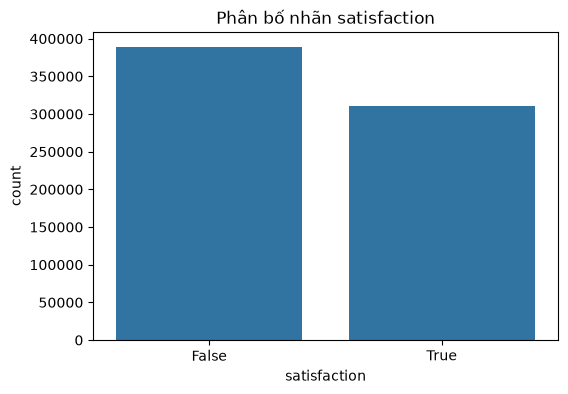

In [33]:
print(df[target_col].value_counts())
print(df[target_col].value_counts(normalize=True).round(4))
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target_col)
plt.title('Phân bố nhãn satisfaction')
plt.show()

## 2. Khám phá dữ liệu (EDA)

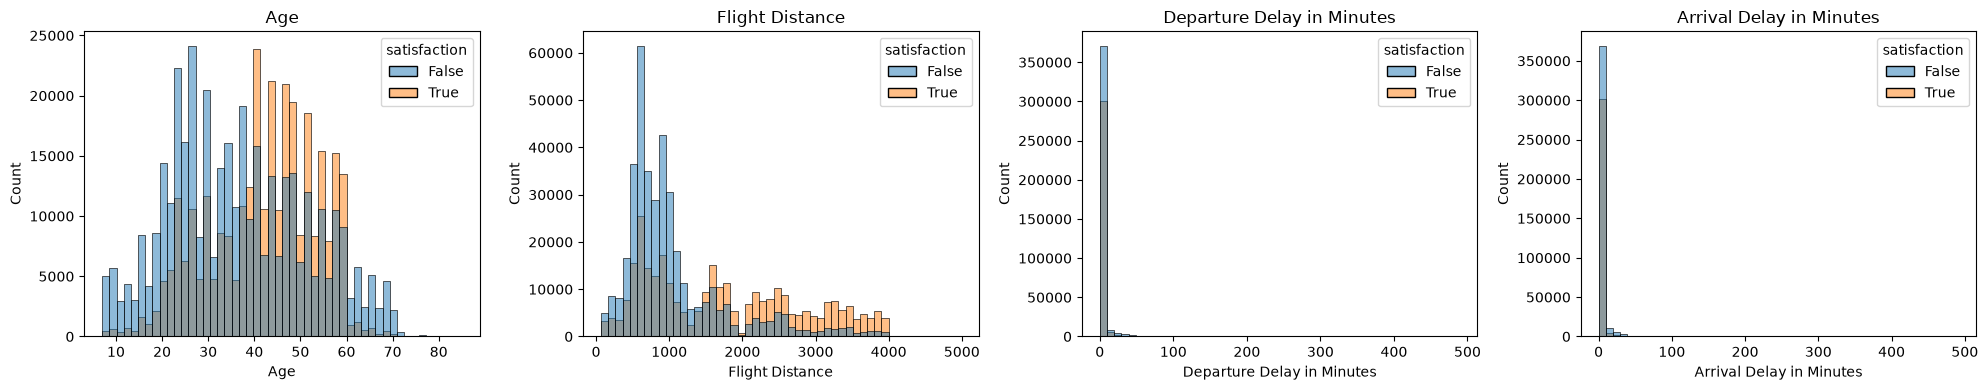

tỉ lệ chuyến không trễ khi cất cánh: 0.9078
tương quan giữa 2 cột trễ: 0.842


In [34]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue=target_col, bins=50, ax=ax[i])
    ax[i].set_title(col)
plt.tight_layout()
plt.show()

print('tỉ lệ chuyến không trễ khi cất cánh:', (df['Departure Delay in Minutes'] == 0).mean().round(4))
print('tương quan giữa 2 cột trễ:', df['Departure Delay in Minutes'].corr(df['Arrival Delay in Minutes']).round(3))

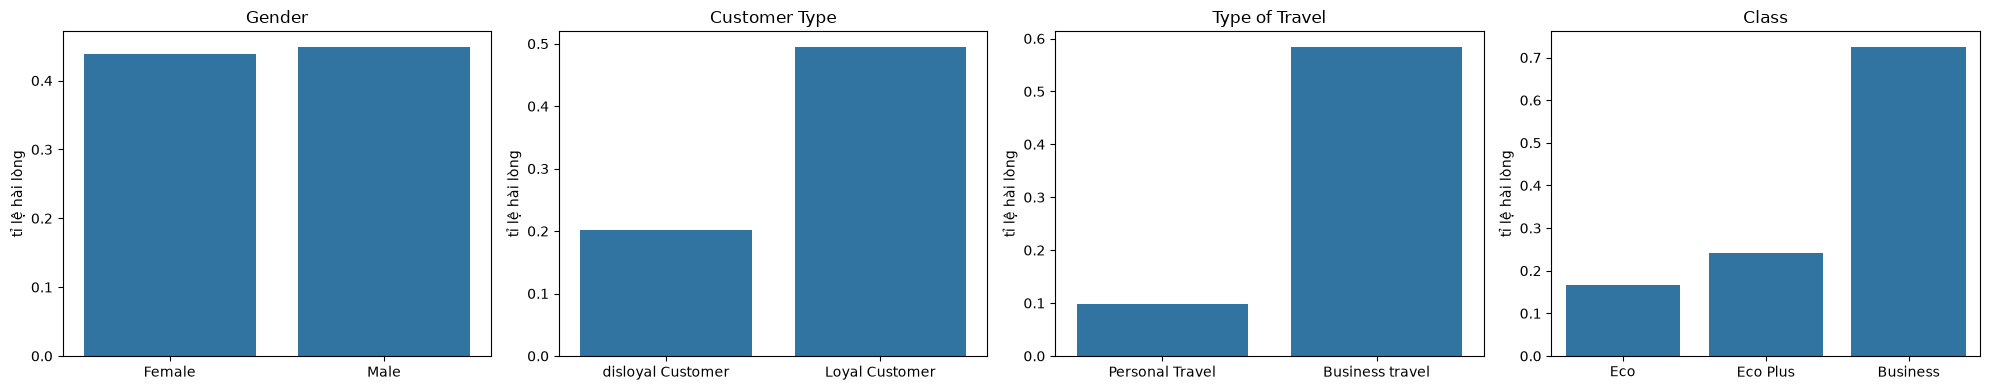

Gender
Female    0.438
Male      0.449
Name: satisfaction, dtype: float64
--------------------------------------------------
Customer Type
Loyal Customer       0.495
disloyal Customer    0.201
Name: satisfaction, dtype: float64
--------------------------------------------------
Type of Travel
Business travel    0.584
Personal Travel    0.097
Name: satisfaction, dtype: float64
--------------------------------------------------
Class
Business    0.725
Eco         0.168
Eco Plus    0.242
Name: satisfaction, dtype: float64
--------------------------------------------------


In [35]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for i, col in enumerate(cate_cols):
    rate = df.groupby(col)[target_col].mean().sort_values()
    sns.barplot(x=rate.index, y=rate.values, ax=ax[i])
    ax[i].set_title(col)
    ax[i].set_xlabel('')
    ax[i].set_ylabel('tỉ lệ hài lòng')
plt.tight_layout()
plt.show()

for col in cate_cols:
    print(df.groupby(col)[target_col].mean().round(3))
    print('-' * 50)

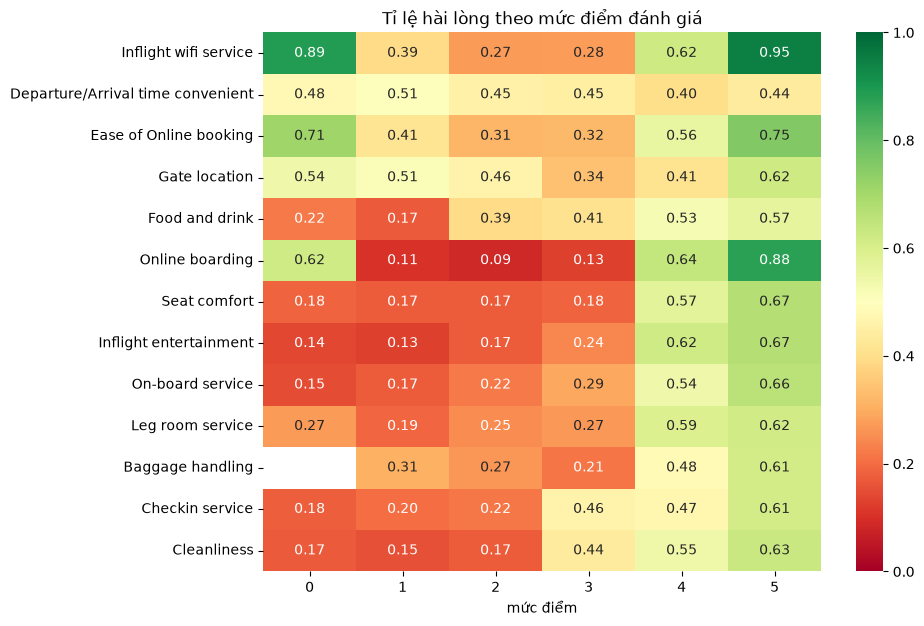

In [36]:
#tỉ lệ hài lòng theo từng mức điểm (0 = khách không đánh giá mục đó)
rate_table = pd.DataFrame({col: df.groupby(col)[target_col].mean() for col in rate_cols}).T
plt.figure(figsize=(9, 7))
sns.heatmap(rate_table, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1)
plt.title('Tỉ lệ hài lòng theo mức điểm đánh giá')
plt.xlabel('mức điểm')
plt.show()

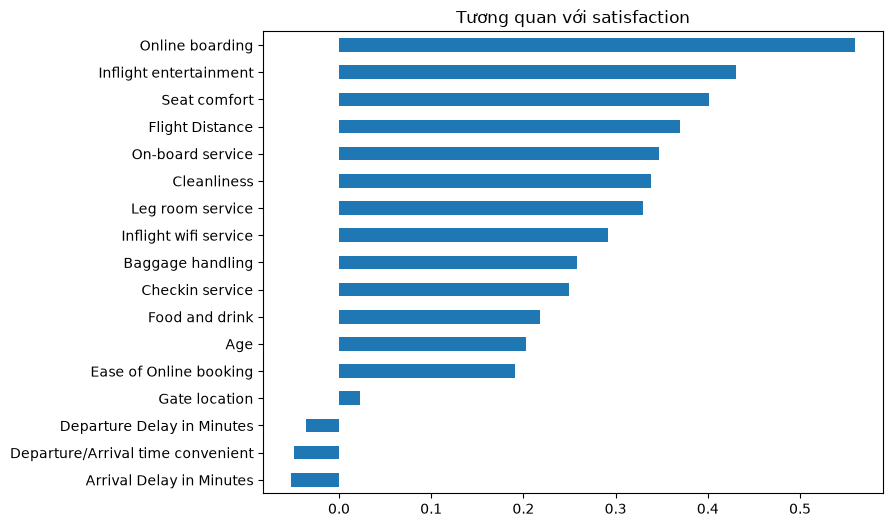

In [37]:
corr_with_target = df[num_cols + rate_cols + [target_col]].corr()[target_col].drop(target_col).sort_values()
plt.figure(figsize=(8, 6))
corr_with_target.plot(kind='barh')
plt.title('Tương quan với satisfaction')
plt.show()

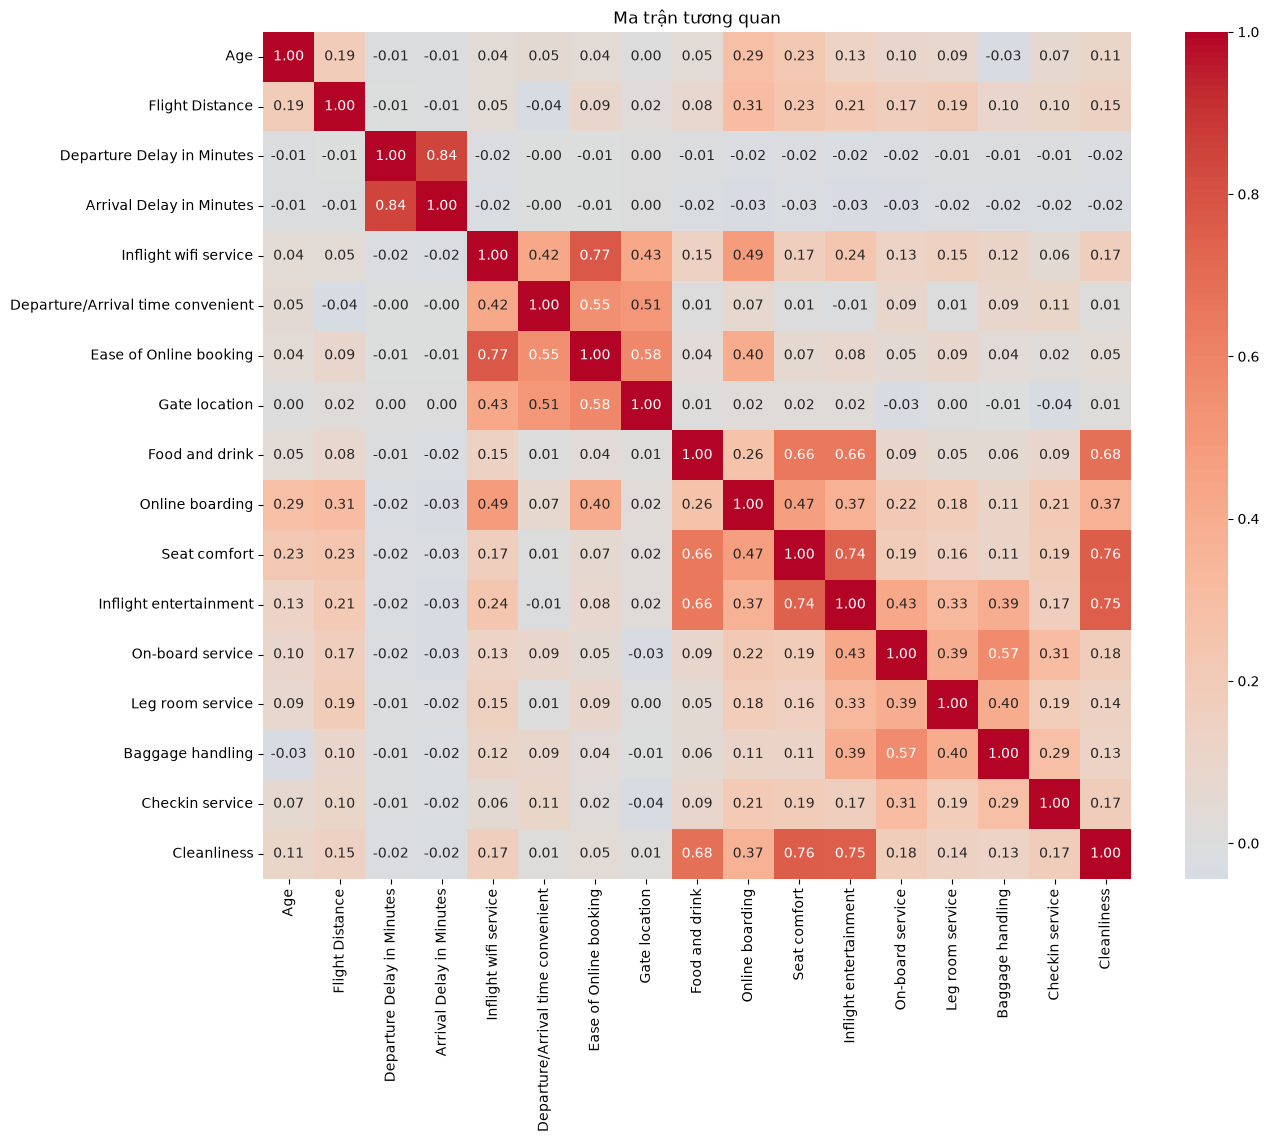

In [38]:
plt.figure(figsize=(14, 11))
sns.heatmap(df[num_cols + rate_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Ma trận tương quan')
plt.show()

In [39]:
#điểm 0 = khách không đánh giá mục đó
zero = df[rate_cols] == 0
print('tỉ lệ dòng có ít nhất 1 điểm 0:', zero.any(axis=1).mean().round(4))
print((zero.mean() * 100).round(2).sort_values(ascending=False))

tỉ lệ dòng có ít nhất 1 điểm 0: 0.0639
Departure/Arrival time convenient    3.68
Ease of Online booking               2.30
Inflight wifi service                1.87
Online boarding                      1.31
Leg room service                     0.24
Gate location                        0.21
Inflight entertainment               0.15
Food and drink                       0.14
Cleanliness                          0.14
Checkin service                      0.13
Seat comfort                         0.12
On-board service                     0.11
Baggage handling                     0.00
dtype: float64


số giá trị khác nhau của Flight Distance: 3474
số tuyến có từ 50 khách trở lên: 1771
count    1771.000
mean        0.607
std         0.268
min         0.028
25%         0.335
50%         0.654
75%         0.853
max         1.000
Name: mean, dtype: float64


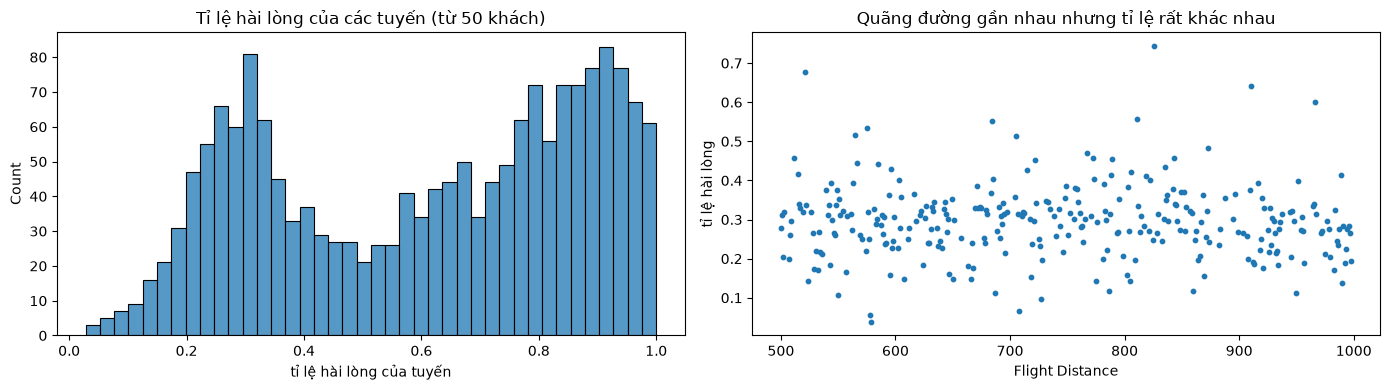

In [40]:
#Flight Distance chỉ có vài nghìn giá trị, mỗi giá trị lặp lại rất nhiều lần -> giống "mã tuyến bay"
print('số giá trị khác nhau của Flight Distance:', df['Flight Distance'].nunique())
route = df.groupby('Flight Distance')[target_col].agg(['mean', 'count'])
route = route[route['count'] >= 50]
print('số tuyến có từ 50 khách trở lên:', len(route))
print(route['mean'].describe().round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(route['mean'], bins=40, ax=ax[0])
ax[0].set_xlabel('tỉ lệ hài lòng của tuyến')
ax[0].set_title('Tỉ lệ hài lòng của các tuyến (từ 50 khách)')
near = route[(route.index >= 500) & (route.index <= 1000)]
ax[1].scatter(near.index, near['mean'], s=10)
ax[1].set_xlabel('Flight Distance')
ax[1].set_ylabel('tỉ lệ hài lòng')
ax[1].set_title('Quãng đường gần nhau nhưng tỉ lệ rất khác nhau')
plt.tight_layout()
plt.show()

Class            Business     Eco  Eco Plus
Type of Travel                             
Business travel    338272  141612     17557
Personal Travel      3940  185792     12462


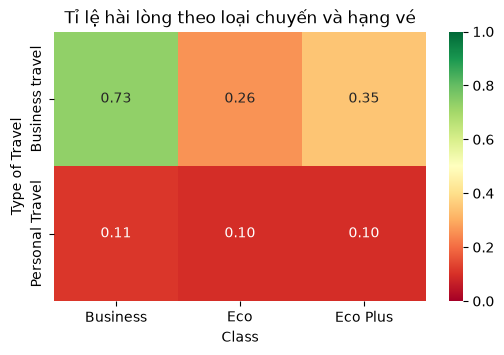

In [41]:
print(pd.crosstab(df['Type of Travel'], df['Class']))
travel_class_rate = pd.crosstab(df['Type of Travel'], df['Class'], values=df[target_col].astype(int), aggfunc='mean')
plt.figure(figsize=(6, 3.5))
sns.heatmap(travel_class_rate, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1)
plt.title('Tỉ lệ hài lòng theo loại chuyến và hạng vé')
plt.show()

## 3. Tiền xử lý dữ liệu

- Chia **80% train / 20% test** trước. 
- **Giá trị thiếu:** `Arrival Delay in Minutes` thiếu 292 dòng => điền bằng median (SimpleImputer nằm trong Pipeline).
- **Dòng trùng:** không có.
- **Ngoại lai:** 2 cột trễ lệch phải rất mạnh => thử lấy log; dùng phát hiện bất thường (Gaussian) để xem có nên bỏ các điểm bất thường không.
- **Mã hoá và chuẩn hoá:** one-hot cho cột phân loại, StandardScaler cho cột số.

In [42]:
X = df.drop(columns=['id', target_col])
y = df[target_col].map({True: 1, False: 0})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
print(X_train.shape)
print(X_test.shape)
print('tỉ lệ hài lòng train:', y_train.mean().round(4), '| test:', y_test.mean().round(4))

(559708, 21)
(139927, 21)
tỉ lệ hài lòng train: 0.4436 | test: 0.4436


### 3.1 Phát hiện bất thường bằng phân phối Gaussian

In [43]:
gauss_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

def to_gauss(data):
    #lấy log để các cột lệch phải gần hình chuông hơn
    G = data[gauss_cols].copy()
    G['Arrival Delay in Minutes'] = G['Arrival Delay in Minutes'].fillna(G['Departure Delay in Minutes'])
    G['Flight Distance'] = np.log(G['Flight Distance'])
    G['Departure Delay in Minutes'] = np.log1p(G['Departure Delay in Minutes'])
    G['Arrival Delay in Minutes'] = np.log1p(G['Arrival Delay in Minutes'])
    return G

def gauss_p(G):
    p = np.ones(len(G))
    for col in gauss_cols:
        p = p * np.exp(-(G[col].values - mu[col]) ** 2 / (2 * sigma2[col])) / np.sqrt(2 * np.pi * sigma2[col])
    return p

G_train = to_gauss(X_train)
mu = G_train.mean()
sigma2 = G_train.var()
p_train = gauss_p(G_train)
epsilon = np.quantile(p_train, 0.01)
is_anomaly = p_train < epsilon

print('epsilon =', epsilon)
print('số điểm bất thường:', is_anomaly.sum(), '/', len(is_anomaly))
print('tỉ lệ hài lòng - bất thường:', y_train[is_anomaly].mean().round(3), '| bình thường:', y_train[~is_anomaly].mean().round(3))
X_train[is_anomaly][gauss_cols].describe().round(1)

epsilon = 1.8278414047287076e-12
số điểm bất thường: 5598 / 559708
tỉ lệ hài lòng - bất thường: 0.315 | bình thường: 0.445


,Age,Flight Distance,Departure Delay in Minutes,Arrival Delay in Minutes
count,5598.0,5598.0,5598.0,5576.0
mean,38.2,1311.3,43.0,39.5
std,14.6,973.8,25.4,25.4
min,7.0,67.0,13.0,12.0
25%,26.0,602.0,33.0,29.0
50%,39.0,908.0,39.0,35.0
75%,49.0,1733.0,45.0,41.0
max,80.0,4983.0,489.0,491.0


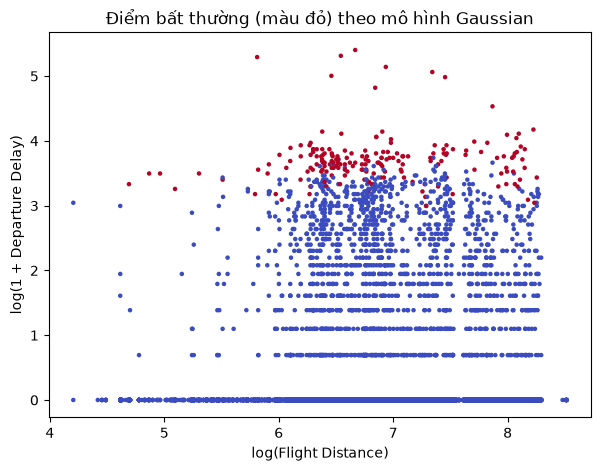

In [44]:
idx = np.random.RandomState(seed).choice(len(G_train), 20000, replace=False)
plt.figure(figsize=(7, 5))
plt.scatter(G_train['Flight Distance'].values[idx], G_train['Departure Delay in Minutes'].values[idx],
            c=is_anomaly[idx], cmap='coolwarm', s=5)
plt.xlabel('log(Flight Distance)')
plt.ylabel('log(1 + Departure Delay)')
plt.title('Điểm bất thường (màu đỏ) theo mô hình Gaussian')
plt.show()

### 3.2 Phân cụm K-means

Phân cụm 13 cột điểm đánh giá của tập train (**không dùng nhãn**). Chọn số cụm $k$ bằng phương pháp khuỷu tay (elbow), rồi thử dùng số thứ tự cụm làm một đặc trưng cho LR.

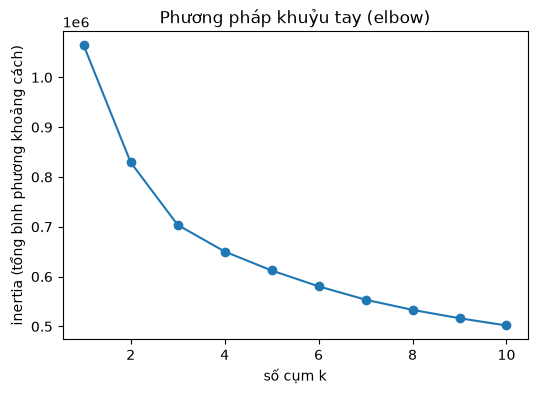

In [45]:
sample = X_train[rate_cols].sample(50000, random_state=seed)
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=3, random_state=seed)
    km.fit(sample)
    inertias.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel('số cụm k')
plt.ylabel('inertia (tổng bình phương khoảng cách)')
plt.title('Phương pháp khuỷu tay (elbow)')
plt.show()

số khách mỗi cụm: [195216 198259 166233]
tỉ lệ hài lòng mỗi cụm: [0.116, 0.697, 0.526]


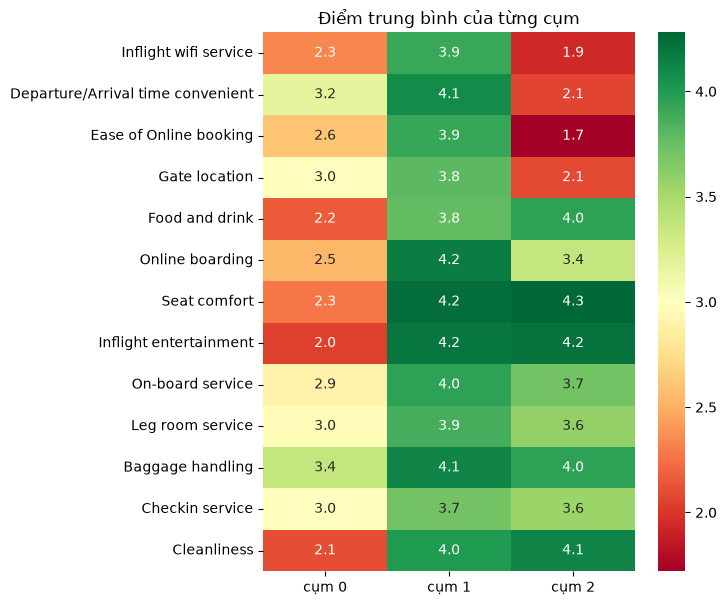

In [46]:
k = 3   #sau k = 3 inertia giảm chậm hẳn
kmeans = KMeans(n_clusters=k, n_init=3, random_state=seed)
kmeans.fit(X_train[rate_cols])
cluster_train = kmeans.predict(X_train[rate_cols])

centers = pd.DataFrame(kmeans.cluster_centers_, columns=rate_cols).T.round(2)
centers.columns = [f'cụm {i}' for i in range(k)]
print('số khách mỗi cụm:', np.bincount(cluster_train))
print('tỉ lệ hài lòng mỗi cụm:', y_train.groupby(cluster_train).mean().round(3).tolist())
plt.figure(figsize=(6, 7))
sns.heatmap(centers, annot=True, fmt='.1f', cmap='RdYlGn')
plt.title('Điểm trung bình của từng cụm')
plt.show()

### 3.3 Tạo đặc trưng mới

Các nhóm đặc trưng được thử thêm cho Logistic Regression

| Tên | Ý nghĩa | Lý do |
|---|---|---|
| `rate_cat` | 13 cột điểm dạng phân loại (one-hot) | quan hệ giữa điểm và sự hài lòng không tuyến tính (điểm 0 = không đánh giá) |
| `zero_flag` | số mục bị chấm 0 | điểm 0 có ý nghĩa riêng |
| `route_te` | target encoding của Flight Distance | Flight Distance giống "mã tuyến bay"; mỗi tuyến được thay bằng tỉ lệ hài lòng của tuyến đó |
| `travel_class` | Type of Travel × Class | 6 tổ hợp có tỉ lệ hài lòng rất khác nhau |
| `log_delay` | log(1 + số phút trễ) | 2 cột trễ lệch phải mạnh |
| `age_cat` | tuổi dạng phân loại | tuổi ảnh hưởng không tuyến tính |
| `cluster` | cụm K-means | nhóm khách có kiểu chấm điểm giống nhau |
| `poly` | đặc trưng đa thức bậc 2: tích từng cặp của 13 điểm, tuổi, quãng đường, độ trễ và các cột phân loại (dạng 0/1) | LR chỉ tạo được ranh giới tuyến tính; thêm tích các cặp giúp LR học được tương tác |


In [47]:
def add_features(data):
    data = data.copy()
    #số mục bị chấm 0
    data['n_zero'] = (data[rate_cols] == 0).sum(axis=1)
    #loại chuyến đi x hạng vé
    data['travel_class'] = data['Type of Travel'] + ' - ' + data['Class']
    #log của độ trễ
    data['log_dep_delay'] = np.log1p(data['Departure Delay in Minutes'])
    data['log_arr_delay'] = np.log1p(data['Arrival Delay in Minutes'])
    #tuổi dạng phân loại
    data['age_cat'] = data['Age'].astype(str)
    #cụm K-means
    data['cluster'] = kmeans.predict(data[rate_cols]).astype(str)
    #cột phân loại dạng 0/1 để tạo đặc trưng đa thức
    data['is_male'] = (data['Gender'] == 'Male').astype(int)
    data['is_loyal'] = (data['Customer Type'] == 'Loyal Customer').astype(int)
    data['is_personal'] = (data['Type of Travel'] == 'Personal Travel').astype(int)
    data['is_business'] = (data['Class'] == 'Business').astype(int)
    data['is_eco_plus'] = (data['Class'] == 'Eco Plus').astype(int)
    return data

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)
X_train_fe.shape

(559708, 32)

In [48]:
handle_num = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
handle_cate = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
handle_route = Pipeline(steps=[
    ('target', TargetEncoder(random_state=seed)),
    ('scaler', StandardScaler())
])
poly_cols = rate_cols + ['Age', 'Flight Distance', 'log_dep_delay', 'log_arr_delay',
                         'is_male', 'is_loyal', 'is_personal', 'is_business', 'is_eco_plus']
handle_poly = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False))
])

def make_processor(features, dense=False):
    num = ['Age', 'Flight Distance']
    cate = list(cate_cols)
    if 'log_delay' in features:
        num += ['log_dep_delay', 'log_arr_delay']
    else:
        num += ['Departure Delay in Minutes', 'Arrival Delay in Minutes']
    if 'rate_cat' in features:
        cate += rate_cols
    else:
        num += rate_cols
    if 'zero_flag' in features:
        num += ['n_zero']
    if 'travel_class' in features:
        cate += ['travel_class']
    if 'age_cat' in features:
        cate += ['age_cat']
    if 'cluster' in features:
        cate += ['cluster']
    transformers = [('num', handle_num, num), ('cate', handle_cate, cate)]
    if 'route_te' in features:
        transformers.append(('route', handle_route, ['Flight Distance']))
    if 'poly' in features:
        transformers.append(('poly', handle_poly, poly_cols))
    #dense=True: luôn trả về ma trận thường (RealMLP không nhận ma trận thưa)
    return ColumnTransformer(transformers=transformers, sparse_threshold=0 if dense else 0.3)

## 4. Baseline

Hai mô hình rất đơn giản để làm mốc: một mô hình tốt phải hơn hẳn hai mốc này.
- **DummyClassifier(strategy='stratified')**: đoán ngẫu nhiên, theo đúng tỉ lệ 2 lớp của tập train.
- **Quy tắc 1 đặc trưng**: `Online boarding ≥ 4` thì dự đoán hài lòng (đặc trưng tương quan mạnh nhất với nhãn).

In [49]:
def get_scores(y_true, y_pred, y_prob=None):
    scores = {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred),
        'recall': recall_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
    }
    if y_prob is not None:
        scores['roc_auc'] = roc_auc_score(y_true, y_prob)
    return scores

#baseline 1: đoán ngẫu nhiên theo tỉ lệ 2 lớp
dummy = DummyClassifier(strategy='stratified', random_state=seed)
dummy_oof = cross_val_predict(dummy, X_train, y_train, cv=cv)
#baseline 2: quy tắc 1 đặc trưng
rule_train = (X_train['Online boarding'] >= 4).astype(int)

baseline_rows = [
    {'model': 'Dummy (ngẫu nhiên)', **get_scores(y_train, dummy_oof)},
    {'model': 'Quy tắc Online boarding >= 4', **get_scores(y_train, rule_train)},
]
pd.DataFrame(baseline_rows).round(4)

,model,accuracy,precision,recall,f1
0,Dummy (ngẫu nhiên),0.5063,0.4435,0.4435,0.4435
1,Quy tắc Online boarding >= 4,0.8065,0.7404,0.8684,0.7993


## 5. Mô hình chính: Logistic Regression

### 5.1 LR với 21 đặc trưng gốc

In [50]:
lr_raw = Pipeline(steps=[
    ('processor', make_processor([])),
    ('model', LogisticRegression(max_iter=1000))
])
scores = cross_validate(lr_raw, X_train_fe, y_train, cv=cv, scoring=['f1', 'roc_auc'], return_train_score=True, n_jobs=5)
print('train f1: ', scores['train_f1'].mean())
print('valid f1: ', scores['test_f1'].mean())
print('valid auc:', scores['test_roc_auc'].mean())

train f1:  0.8609204812182867
valid f1:  0.8608977835503999
valid auc: 0.9218602833758828


### 5.2 Thêm từng nhóm đặc trưng

Thêm lần lượt từng nhóm ở mục 3.3 và đo F1 bằng 5-fold CV. Nhóm nào làm **F1 tăng thì giữ lại**, không tăng thì bỏ.

In [51]:
candidates = {
    'rate_cat': 'Điểm đánh giá dạng phân loại',
    'zero_flag': 'Số mục bị chấm 0',
    'route_te': 'Mã tuyến bay (target encoding)',
    'travel_class': 'Loại chuyến x hạng vé',
    'log_delay': 'Log độ trễ',
    'age_cat': 'Tuổi dạng phân loại',
    'cluster': 'Cụm K-means',
    'poly': 'Đặc trưng đa thức bậc 2',
}

def cv_f1(features):
    pipe = Pipeline(steps=[
        ('processor', make_processor(features)),
        ('model', LogisticRegression(max_iter=1000))
    ])
    n_jobs = 1 if 'poly' in features else 5
    scores = cross_validate(pipe, X_train_fe, y_train, cv=cv, scoring='f1', n_jobs=n_jobs)
    return scores['test_score'].mean()

selected = []
best_f1 = cv_f1(selected)
rows = [{'bước': 'LR 21 đặc trưng gốc', 'f1': best_f1, 'thay đổi': 0, 'giữ lại': ''}]
for feat, desc in candidates.items():
    start = time.time()
    f1 = cv_f1(selected + [feat])
    keep = f1 > best_f1
    rows.append({'bước': '+ ' + desc, 'f1': f1, 'thay đổi': f1 - best_f1, 'giữ lại': 'có' if keep else 'không'})
    print(f'{feat:13s} f1 = {f1:.5f} ({f1 - best_f1:+.5f}) -> {"giữ" if keep else "bỏ"} | {time.time() - start:.0f}s')
    if keep:
        selected.append(feat)
        best_f1 = f1

ablation = pd.DataFrame(rows)
print('đặc trưng được chọn:', selected)
ablation.round(5)

rate_cat      f1 = 0.89750 (+0.03660) -> giữ | 16s
zero_flag     f1 = 0.89748 (-0.00001) -> bỏ | 18s
route_te      f1 = 0.89759 (+0.00009) -> giữ | 16s
travel_class  f1 = 0.89757 (-0.00002) -> bỏ | 18s
log_delay     f1 = 0.89773 (+0.00014) -> giữ | 23s
age_cat       f1 = 0.89794 (+0.00021) -> giữ | 27s
cluster       f1 = 0.89848 (+0.00054) -> giữ | 27s
poly          f1 = 0.90670 (+0.00822) -> giữ | 292s
đặc trưng được chọn: ['rate_cat', 'route_te', 'log_delay', 'age_cat', 'cluster', 'poly']


,bước,f1,thay đổi,giữ lại
0,LR 21 đặc trưng gốc,0.86090,0.00000,
1,+ Điểm đánh giá dạng phân loại,0.89750,0.03660,có
2,+ Số mục bị chấm 0,0.89748,-0.00001,không
3,+ Mã tuyến bay (target encoding),0.89759,0.00009,có
4,+ Loại chuyến x hạng vé,0.89757,-0.00002,không
5,+ Log độ trễ,0.89773,0.00014,có
6,+ Tuổi dạng phân loại,0.89794,0.00021,có
7,+ Cụm K-means,0.89848,0.00054,có
8,+ Đặc trưng đa thức bậc 2,0.90670,0.00822,có


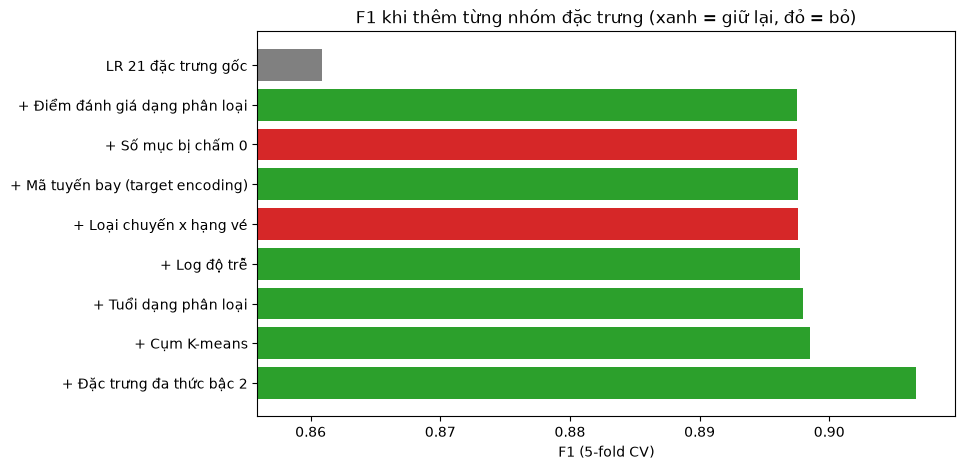

In [52]:
plt.figure(figsize=(9, 5))
colors = ['gray'] + ['tab:green' if k == 'có' else 'tab:red' for k in ablation['giữ lại'][1:]]
plt.barh(ablation['bước'][::-1], ablation['f1'][::-1], color=colors[::-1])
plt.xlim(ablation['f1'].min() - 0.005, ablation['f1'].max() + 0.003)
plt.xlabel('F1 (5-fold CV)')
plt.title('F1 khi thêm từng nhóm đặc trưng (xanh = giữ lại, đỏ = bỏ)')
plt.show()

### 5.3 Có nên bỏ các điểm bất thường khi train?


In [53]:
lr_best = Pipeline(steps=[
    ('processor', make_processor(selected)),
    ('model', LogisticRegression(max_iter=1000))
])
f1_keep = []
f1_drop = []
for train_idx, valid_idx in cv.split(X_train_fe, y_train):
    X_tr, y_tr = X_train_fe.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train_fe.iloc[valid_idx], y_train.iloc[valid_idx]
    normal = ~is_anomaly[train_idx]
    lr_best.fit(X_tr, y_tr)
    f1_keep.append(f1_score(y_va, lr_best.predict(X_va)))
    lr_best.fit(X_tr[normal], y_tr[normal])
    f1_drop.append(f1_score(y_va, lr_best.predict(X_va)))

print('giữ điểm bất thường: f1 =', np.mean(f1_keep).round(5))
print('bỏ điểm bất thường:  f1 =', np.mean(f1_drop).round(5))

giữ điểm bất thường: f1 = 0.9067
bỏ điểm bất thường:  f1 = 0.90666


### 5.4 Chọn λ bằng GridSearchCV và xem bias / variance

Thử nhiều giá trị `C` = 1/λ. Vẽ lỗi train và lỗi cross-validation (lỗi = 1 − F1) theo λ:
cả hai lỗi đều cao là **high bias** (underfit); lỗi train thấp nhưng lỗi CV cao là **high variance** (overfit).

best params:  {'model__C': 1}
best f1:  0.9066970907396991
31.2 phút


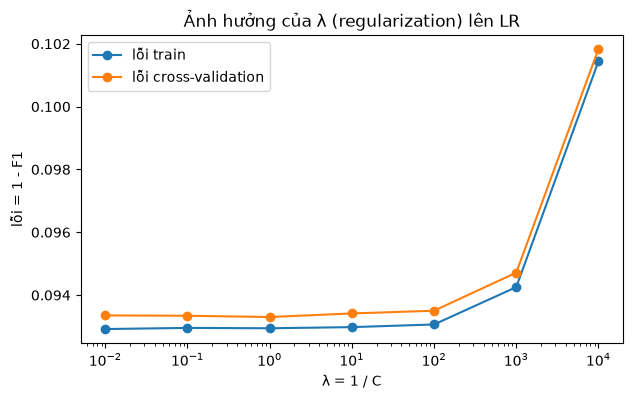

In [54]:
param_grid = {'model__C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]}
start = time.time()
grid_lr = GridSearchCV(lr_best, param_grid, cv=cv, scoring='f1', return_train_score=True, n_jobs=1, refit=False)
grid_lr.fit(X_train_fe, y_train)
print('best params: ', grid_lr.best_params_)
print('best f1: ', grid_lr.best_score_)
print(f'{(time.time() - start) / 60:.1f} phút')

lam = 1 / np.array(param_grid['model__C'])
plt.figure(figsize=(7, 4))
plt.plot(lam, 1 - grid_lr.cv_results_['mean_train_score'], marker='o', label='lỗi train')
plt.plot(lam, 1 - grid_lr.cv_results_['mean_test_score'], marker='o', label='lỗi cross-validation')
plt.xscale('log')
plt.xlabel('λ = 1 / C')
plt.ylabel('lỗi = 1 - F1')
plt.title('Ảnh hưởng của λ (regularization) lên LR')
plt.legend()
plt.show()

lr_best.set_params(**grid_lr.best_params_)
tuning_rows = [{'model': 'LR (thêm đặc trưng)',
                'f1 mặc định': grid_lr.cv_results_['mean_test_score'][param_grid['model__C'].index(1)],
                'f1 sau GridSearch': grid_lr.best_score_,
                'tham số tốt nhất': str(grid_lr.best_params_).replace('model__', '')}]

### 5.5 Learning curve


LR (gốc) - lỗi train: [0.1281 0.1348 0.1371 0.1374 0.1389 0.1391] | lỗi CV: [0.1397 0.1385 0.139  0.139  0.139  0.1391]
LR (thêm đặc trưng) - lỗi train: [0.0718 0.0893 0.0917 0.0919 0.0924 0.0929] | lỗi CV: [0.1115 0.096  0.0947 0.0937 0.0935 0.0933]


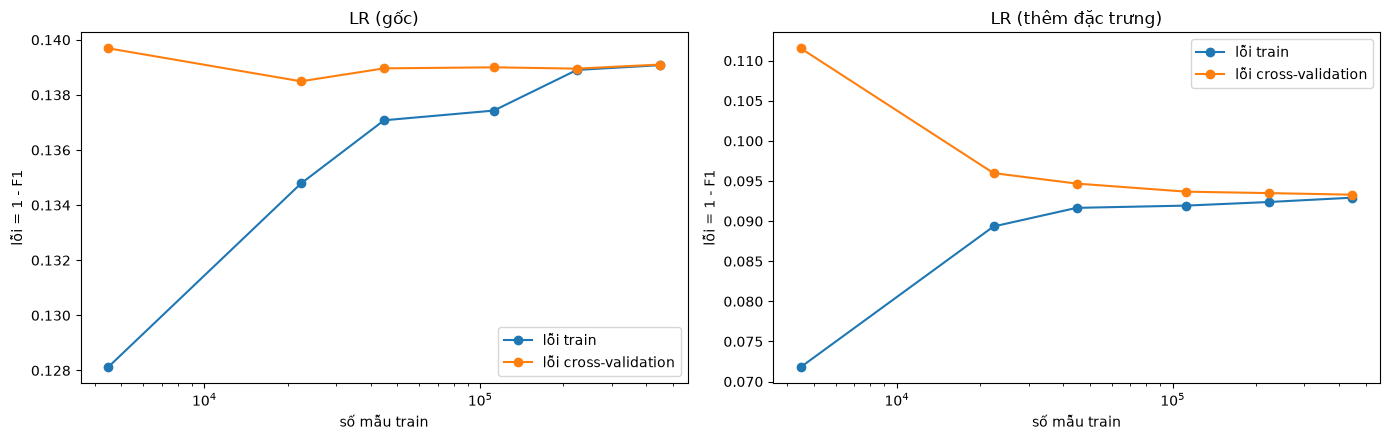

In [55]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for i, (name, pipe, n_jobs) in enumerate([('LR (gốc)', lr_raw, 5), ('LR (thêm đặc trưng)', lr_best, 1)]):
    sizes, train_scores, valid_scores = learning_curve(pipe, X_train_fe, y_train, cv=cv, scoring='f1', n_jobs=n_jobs,
                                                       train_sizes=[0.01, 0.05, 0.1, 0.25, 0.5, 1.0])
    ax[i].plot(sizes, 1 - train_scores.mean(axis=1), marker='o', label='lỗi train')
    ax[i].plot(sizes, 1 - valid_scores.mean(axis=1), marker='o', label='lỗi cross-validation')
    ax[i].set_xscale('log')
    ax[i].set_xlabel('số mẫu train')
    ax[i].set_ylabel('lỗi = 1 - F1')
    ax[i].set_title(name)
    ax[i].legend()
    print(name, '- lỗi train:', (1 - train_scores.mean(axis=1)).round(4), '| lỗi CV:', (1 - valid_scores.mean(axis=1)).round(4))
plt.tight_layout()
plt.show()

### 5.6 Dự đoán out-of-fold và dự đoán tập test

Với mỗi mô hình: `cross_val_predict` cho xác suất **out-of-fold** trên 80% train (mỗi dòng được dự đoán bởi mô hình không học dòng đó), dùng để chọn ngưỡng ở mục 8. Sau đó train lại trên toàn bộ 80% và dự đoán 20% test.

In [56]:
oof_prob = {}
test_prob = {}
fitted = {}

def oof_and_test(name, pipe, n_jobs=5):
    start = time.time()
    oof_prob[name] = cross_val_predict(pipe, X_train_fe, y_train, cv=cv, method='predict_proba', n_jobs=n_jobs)[:, 1]
    pipe.fit(X_train_fe, y_train)
    test_prob[name] = pipe.predict_proba(X_test_fe)[:, 1]
    fitted[name] = pipe
    print(f'{name}: cv f1 (ngưỡng 0.5) = {f1_score(y_train, oof_prob[name] >= 0.5):.4f} | {(time.time() - start) / 60:.1f} phút')

oof_and_test('LR (gốc)', lr_raw)
oof_and_test('LR (thêm đặc trưng)', lr_best, n_jobs=1)

LR (gốc): cv f1 (ngưỡng 0.5) = 0.8609 | 1.0 phút
LR (thêm đặc trưng): cv f1 (ngưỡng 0.5) = 0.9067 | 6.5 phút


### 5.7 Hệ số của mô hình

Các cột đã được chuẩn hoá nên độ lớn của hệ số cho biết mức ảnh hưởng: hệ số dương làm tăng xác suất hài lòng, hệ số âm làm giảm.

số đặc trưng sau khi biến đổi: 26 -> 422


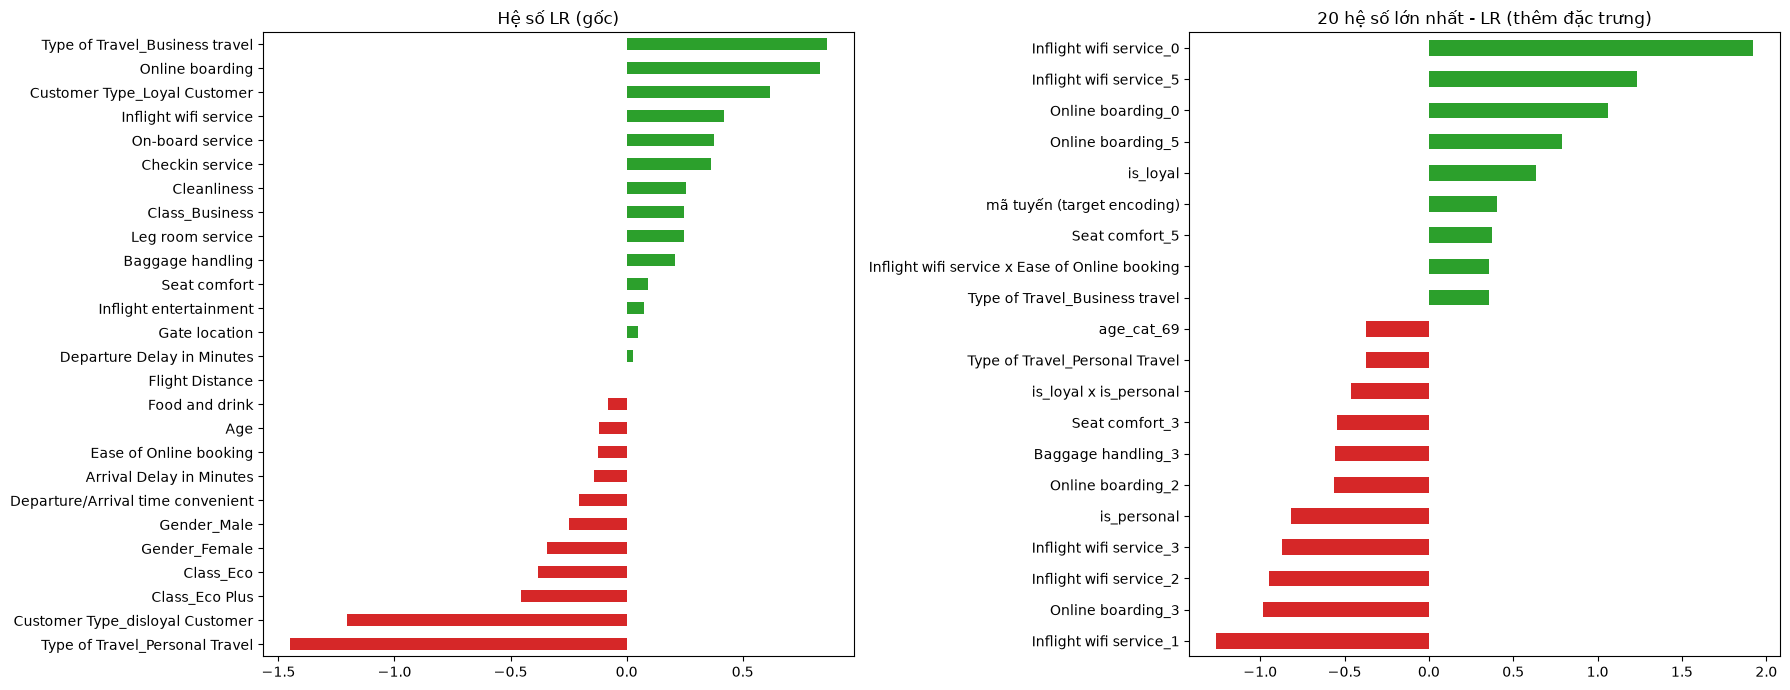

In [57]:
def feature_names(processor):
    #tên cột sau khi biến đổi (bỏ tiền tố 'num__', 'cate__')
    names = []
    for n in processor.get_feature_names_out():
        group, col = n.split('__', 1)
        names.append('mã tuyến (target encoding)' if group == 'route' else col)
    return names

def lr_coef(name):
    processor = fitted[name].named_steps['processor']
    names = feature_names(processor)
    if 'poly' in processor.named_transformers_:
        powers = processor.named_transformers_['poly'].named_steps['poly'].powers_
        poly_names = [' x '.join(np.array(poly_cols)[p == 1]) for p in powers]
        names = names[:len(names) - len(poly_names)] + poly_names
    return pd.Series(fitted[name].named_steps['model'].coef_[0], index=names)

coef_raw = lr_coef('LR (gốc)').sort_values()
coef_best = lr_coef('LR (thêm đặc trưng)')
top = coef_best[coef_best.abs().sort_values(ascending=False).head(20).index].sort_values()
print('số đặc trưng sau khi biến đổi:', len(coef_raw), '->', len(coef_best))

fig, ax = plt.subplots(1, 2, figsize=(18, 7))
coef_raw.plot(kind='barh', ax=ax[0], color=['tab:red' if v < 0 else 'tab:green' for v in coef_raw])
ax[0].set_title('Hệ số LR (gốc)')
top.plot(kind='barh', ax=ax[1], color=['tab:red' if v < 0 else 'tab:green' for v in top])
ax[1].set_title('20 hệ số lớn nhất - LR (thêm đặc trưng)')
plt.tight_layout()
plt.show()

## 6. Mô hình so sánh: Decision Tree, LightGBM, XGBoost, RealMLP

Mỗi mô hình chạy trên 2 bộ đặc trưng:
- **gốc**: 21 cột ban đầu.
- **thêm đặc trưng**: các nhóm đặc trưng mà LR đã chọn ở mục 5.2, trừ đặc trưng đa thức. Lý do: mô hình cây và mạng nơ-ron tự học được tương tác giữa các cột, còn thêm khoảng 250 cột đa thức làm thời gian chạy tăng khoảng 10 lần.

Decision Tree, LightGBM, XGBoost: đo F1 với tham số mặc định, rồi tinh chỉnh riêng cho từng bộ bằng GridSearchCV (5-fold, scoring F1).
RealMLP (deep learning, thư viện pytabkit) không tinh chỉnh, chỉ chạy 5-fold như các mô hình khác.

In [58]:
tree_features = [f for f in selected if f != 'poly']
feature_sets = {'gốc': [], 'thêm đặc trưng': tree_features}
print('bộ "thêm đặc trưng":', tree_features)
grids = {}

def tune(model_name, model, param_grid):
    for set_name, features in feature_sets.items():
        name = f'{model_name} ({set_name})'
        start = time.time()
        pipe = Pipeline(steps=[
            ('processor', make_processor(features)),
            ('model', clone(model))
        ])
        default_f1 = cross_validate(pipe, X_train_fe, y_train, cv=cv, scoring='f1', n_jobs=5)['test_score'].mean()
        grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='f1', n_jobs=5, refit=False)
        grid.fit(X_train_fe, y_train)
        grids[name] = grid
        tuning_rows.append({'model': name, 'f1 mặc định': default_f1, 'f1 sau GridSearch': grid.best_score_,
                            'tham số tốt nhất': str(grid.best_params_).replace('model__', '')})
        print(f'{name}: f1 mặc định {default_f1:.4f} -> sau GridSearch {grid.best_score_:.4f} | {grid.best_params_}')
        pipe.set_params(**grid.best_params_)
        oof_and_test(name, pipe)
        print(f'   tổng thời gian: {(time.time() - start) / 60:.1f} phút')

bộ "thêm đặc trưng": ['rate_cat', 'route_te', 'log_delay', 'age_cat', 'cluster']


In [59]:
tune('Decision Tree', DecisionTreeClassifier(random_state=seed), {
    'model__max_depth': [6, 8, 10, 12, 15, 20],
    'model__min_samples_leaf': [1, 20, 100],
})

Decision Tree (gốc): f1 mặc định 0.8493 -> sau GridSearch 0.9101 | {'model__max_depth': 20, 'model__min_samples_leaf': 20}
Decision Tree (gốc): cv f1 (ngưỡng 0.5) = 0.9100 | 0.9 phút
   tổng thời gian: 8.4 phút
Decision Tree (thêm đặc trưng): f1 mặc định 0.8545 -> sau GridSearch 0.9103 | {'model__max_depth': 20, 'model__min_samples_leaf': 20}
Decision Tree (thêm đặc trưng): cv f1 (ngưỡng 0.5) = 0.9104 | 6.8 phút
   tổng thời gian: 58.1 phút


In [60]:
tune('LightGBM', LGBMClassifier(random_state=seed, n_jobs=2, verbose=-1, importance_type='gain'), {
    'model__n_estimators': [500, 1000],
    'model__learning_rate': [0.05, 0.1],
    'model__num_leaves': [31, 63, 127],
})

LightGBM (gốc): f1 mặc định 0.9145 -> sau GridSearch 0.9157 | {'model__learning_rate': 0.05, 'model__n_estimators': 500, 'model__num_leaves': 127}
LightGBM (gốc): cv f1 (ngưỡng 0.5) = 0.9157 | 2.4 phút
   tổng thời gian: 27.0 phút
LightGBM (thêm đặc trưng): f1 mặc định 0.9148 -> sau GridSearch 0.9162 | {'model__learning_rate': 0.05, 'model__n_estimators': 500, 'model__num_leaves': 127}
LightGBM (thêm đặc trưng): cv f1 (ngưỡng 0.5) = 0.9162 | 1.8 phút
   tổng thời gian: 26.6 phút


In [61]:
tune('XGBoost', XGBClassifier(random_state=seed, n_jobs=2, tree_method='hist', importance_type='gain'), {
    'model__n_estimators': [500, 1000],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [4, 6, 8],
})

XGBoost (gốc): f1 mặc định 0.9152 -> sau GridSearch 0.9158 | {'model__learning_rate': 0.1, 'model__max_depth': 6, 'model__n_estimators': 1000}
XGBoost (gốc): cv f1 (ngưỡng 0.5) = 0.9158 | 3.1 phút
   tổng thời gian: 24.2 phút
XGBoost (thêm đặc trưng): f1 mặc định 0.9149 -> sau GridSearch 0.9159 | {'model__learning_rate': 0.05, 'model__max_depth': 8, 'model__n_estimators': 500}
XGBoost (thêm đặc trưng): cv f1 (ngưỡng 0.5) = 0.9159 | 2.9 phút
   tổng thời gian: 30.0 phút


In [62]:
logging.disable(logging.INFO)   #ẩn các dòng thông báo của thư viện khi train
for set_name, features in feature_sets.items():
    pipe = Pipeline(steps=[
        ('processor', make_processor(features, dense=True)),
        ('model', RealMLP_TD_Classifier(device='cpu', random_state=seed, n_epochs=20, batch_size=1024,
                                        plr_sigma=32, verbosity=0))
    ])
    oof_and_test(f'RealMLP ({set_name})', pipe)

RealMLP (gốc): cv f1 (ngưỡng 0.5) = 0.9158 | 41.0 phút
RealMLP (thêm đặc trưng): cv f1 (ngưỡng 0.5) = 0.9164 | 69.7 phút


## 7. Mô hình kết hợp: LR + LightGBM

Lấy trung bình xác suất của LR (thêm đặc trưng) và LightGBM (bộ đặc trưng có F1 cross-validation cao hơn).

In [63]:
def best_set(model_name):
    #bộ đặc trưng có f1 cross-validation cao hơn
    if grids[f'{model_name} (gốc)'].best_score_ >= grids[f'{model_name} (thêm đặc trưng)'].best_score_:
        return f'{model_name} (gốc)'
    return f'{model_name} (thêm đặc trưng)'

lgb_name = best_set('LightGBM')
oof_prob['LR + LightGBM'] = (oof_prob['LR (thêm đặc trưng)'] + oof_prob[lgb_name]) / 2
test_prob['LR + LightGBM'] = (test_prob['LR (thêm đặc trưng)'] + test_prob[lgb_name]) / 2
print('dùng', lgb_name)
print('cv f1 (ngưỡng 0.5):', round(f1_score(y_train, oof_prob['LR + LightGBM'] >= 0.5), 4))

dùng LightGBM (thêm đặc trưng)
cv f1 (ngưỡng 0.5): 0.9147


## 8. Chọn ngưỡng quyết định theo cross-validation


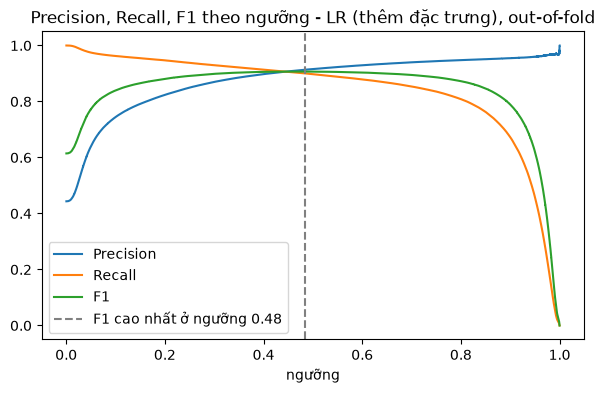

In [64]:
precision, recall, thr = precision_recall_curve(y_train, oof_prob['LR (thêm đặc trưng)'])
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best_t = thr[np.argmax(f1[:-1])]
plt.figure(figsize=(7, 4))
plt.plot(thr, precision[:-1], label='Precision')
plt.plot(thr, recall[:-1], label='Recall')
plt.plot(thr, f1[:-1], label='F1')
plt.axvline(best_t, color='gray', linestyle='--', label=f'F1 cao nhất ở ngưỡng {best_t:.2f}')
plt.xlabel('ngưỡng')
plt.title('Precision, Recall, F1 theo ngưỡng - LR (thêm đặc trưng), out-of-fold')
plt.legend()
plt.show()

In [65]:
thresholds = np.arange(0.10, 0.91, 0.01)
best_threshold = {}
cv_rows = []
for name, prob in oof_prob.items():
    f1_list = [f1_score(y_train, prob >= t) for t in thresholds]
    best_threshold[name] = thresholds[np.argmax(f1_list)].round(2)
    pred = (prob >= best_threshold[name]).astype(int)
    cv_rows.append({'model': name, 'ngưỡng': best_threshold[name], 'f1 (ngưỡng 0.5)': f1_score(y_train, prob >= 0.5),
                    **get_scores(y_train, pred, prob)})
cv_results = pd.DataFrame(cv_rows).sort_values('f1', ascending=False).round(4)
cv_results

,model,ngưỡng,f1 (ngưỡng 0.5),accuracy,precision,recall,f1,roc_auc
9,RealMLP (thêm đặc trưng),0.48,0.9164,0.9265,0.9238,0.9093,0.9165,0.9590
5,LightGBM (thêm đặc trưng),0.46,0.9162,0.9263,0.9223,0.9106,0.9164,0.9596
8,RealMLP (gốc),0.47,0.9158,0.9261,0.9226,0.9098,0.9161,0.9580
4,LightGBM (gốc),0.44,0.9157,0.9258,0.9192,0.9128,0.9160,0.9584
6,XGBoost (gốc),0.47,0.9158,0.9260,0.9223,0.9098,0.9160,0.9581
7,XGBoost (thêm đặc trưng),0.48,0.9159,0.9261,0.9239,0.9081,0.9160,0.9595
10,LR + LightGBM,0.46,0.9147,0.9249,0.9197,0.9102,0.9149,0.9583
3,Decision Tree (thêm đặc trưng),0.49,0.9104,0.9212,0.9171,0.9040,0.9105,0.9511
2,Decision Tree (gốc),0.49,0.9100,0.9209,0.9182,0.9021,0.9101,0.9500
1,LR (thêm đặc trưng),0.46,0.9067,0.9176,0.9094,0.9043,0.9068,0.9544


## 9. Đánh giá trên tập test (20%)

Mỗi mô hình dùng ngưỡng đã chọn ở mục 8. F1 là thước đo chính.

In [66]:
test_rows = []
for name, prob in test_prob.items():
    pred = (prob >= best_threshold[name]).astype(int)
    test_rows.append({'model': name, 'ngưỡng': best_threshold[name], **get_scores(y_test, pred, prob)})
dummy.fit(X_train, y_train)
test_rows.append({'model': 'Dummy (ngẫu nhiên)', **get_scores(y_test, dummy.predict(X_test))})
test_rows.append({'model': 'Quy tắc Online boarding >= 4', **get_scores(y_test, (X_test['Online boarding'] >= 4).astype(int))})
test_results = pd.DataFrame(test_rows).sort_values('f1', ascending=False).round(4)
test_results

,model,ngưỡng,accuracy,precision,recall,f1,roc_auc
4,LightGBM (gốc),0.44,0.9246,0.9190,0.9104,0.9146,0.9575
8,RealMLP (gốc),0.47,0.9249,0.9222,0.9072,0.9146,0.9570
5,LightGBM (thêm đặc trưng),0.46,0.9247,0.9216,0.9075,0.9145,0.9587
9,RealMLP (thêm đặc trưng),0.48,0.9249,0.9249,0.9040,0.9144,0.9584
6,XGBoost (gốc),0.47,0.9244,0.9217,0.9065,0.9140,0.9573
7,XGBoost (thêm đặc trưng),0.48,0.9244,0.9229,0.9052,0.9140,0.9587
10,LR + LightGBM,0.46,0.9233,0.9185,0.9075,0.9130,0.9574
2,Decision Tree (gốc),0.49,0.9204,0.9187,0.9004,0.9094,0.9491
3,Decision Tree (thêm đặc trưng),0.49,0.9197,0.9183,0.8989,0.9085,0.9500
1,LR (thêm đặc trưng),0.46,0.9163,0.9088,0.9019,0.9053,0.9535


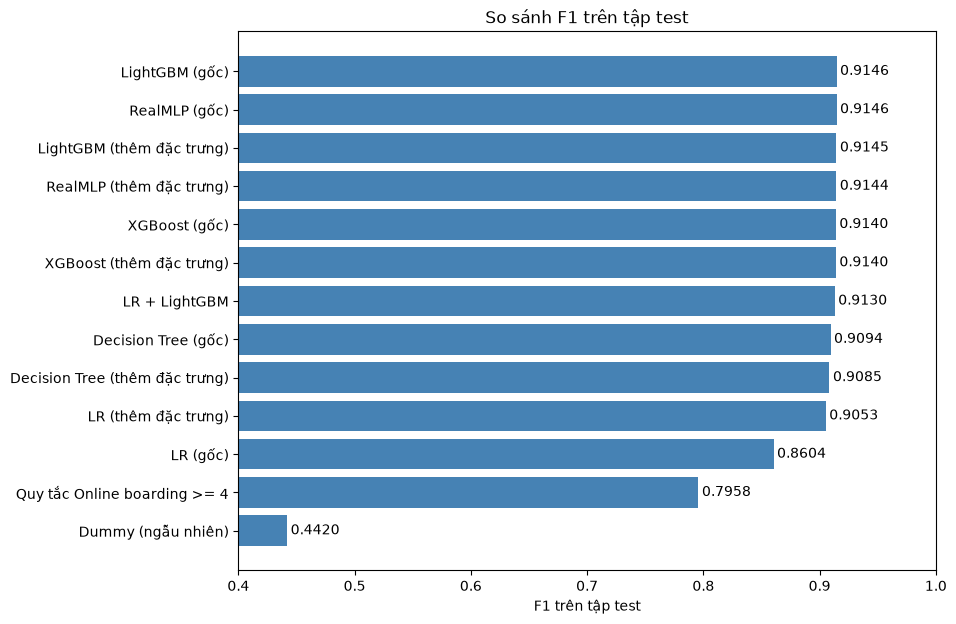

In [67]:
plt.figure(figsize=(9, 7))
plt.barh(test_results['model'][::-1], test_results['f1'][::-1], color='steelblue')
for i, v in enumerate(test_results['f1'][::-1]):
    plt.text(v + 0.003, i, f'{v:.4f}', va='center')
plt.xlim(0.4, 1.0)
plt.xlabel('F1 trên tập test')
plt.title('So sánh F1 trên tập test')
plt.show()

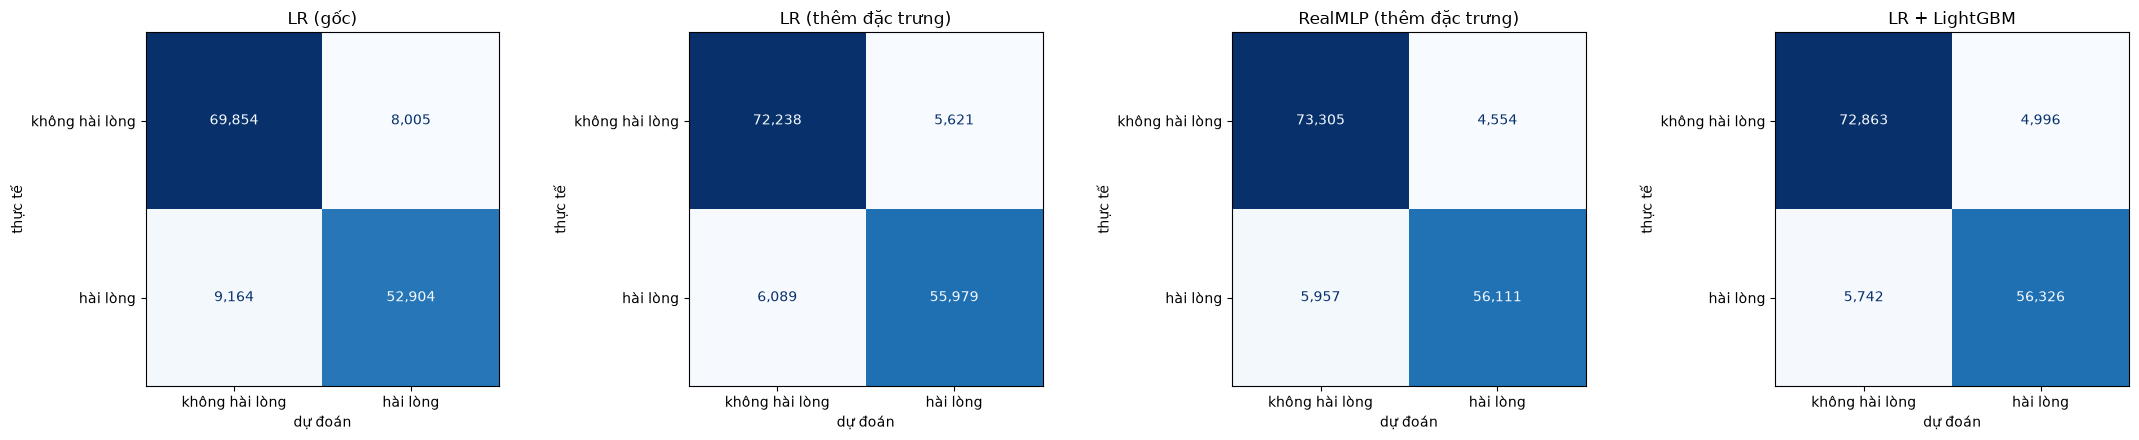

In [68]:
#mô hình so sánh tốt nhất theo cross-validation (không chọn theo test)
best_other = cv_results[~cv_results['model'].str.startswith('LR')]['model'].iloc[0]
show = ['LR (gốc)', 'LR (thêm đặc trưng)', best_other, 'LR + LightGBM']
fig, ax = plt.subplots(1, 4, figsize=(22, 4.5))
for i, name in enumerate(show):
    pred = (test_prob[name] >= best_threshold[name]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['không hài lòng', 'hài lòng']).plot(
        ax=ax[i], cmap='Blues', values_format=',d', colorbar=False)
    ax[i].set_title(name)
    ax[i].set_xlabel('dự đoán')
    ax[i].set_ylabel('thực tế')
plt.tight_layout()
plt.show()

## 10. Thí nghiệm mở rộng

### 10.1 Thay đổi tỉ lệ tập test: 10%, 20%, 30%


In [69]:
X_fe = add_features(X)
final_models = {
    'LR (thêm đặc trưng)': fitted['LR (thêm đặc trưng)'],
    'Decision Tree': fitted[best_set('Decision Tree')],
    'LightGBM': fitted[lgb_name],
    'XGBoost': fitted[best_set('XGBoost')],
}
ratio_rows = []
for test_size in [0.1, 0.2, 0.3]:
    start = time.time()
    X_tr, X_te, y_tr, y_te = train_test_split(X_fe, y, test_size=test_size, random_state=seed, stratify=y)
    probs = {}
    for name, model in final_models.items():
        model = clone(model)
        model.fit(X_tr, y_tr)
        probs[name] = model.predict_proba(X_te)[:, 1]
    probs['LR + LightGBM'] = (probs['LR (thêm đặc trưng)'] + probs['LightGBM']) / 2
    for name, prob in probs.items():
        ratio_rows.append({'test_size': test_size, 'model': name, **get_scores(y_te, (prob >= 0.5).astype(int), prob)})
    print(f'xong test_size = {test_size} | {(time.time() - start) / 60:.1f} phút')

ratio_results = pd.DataFrame(ratio_rows)
ratio_results.pivot(index='model', columns='test_size', values='f1').round(4)

xong test_size = 0.1 | 5.6 phút
xong test_size = 0.2 | 4.9 phút
xong test_size = 0.3 | 4.2 phút


test_size,0.1,0.2,0.3
model,,,
Decision Tree,0.9099,0.9084,0.9085
LR (thêm đặc trưng),0.9055,0.9047,0.9055
LR + LightGBM,0.9132,0.9125,0.9130
LightGBM,0.9154,0.9144,0.9149
XGBoost,0.9148,0.9140,0.9146


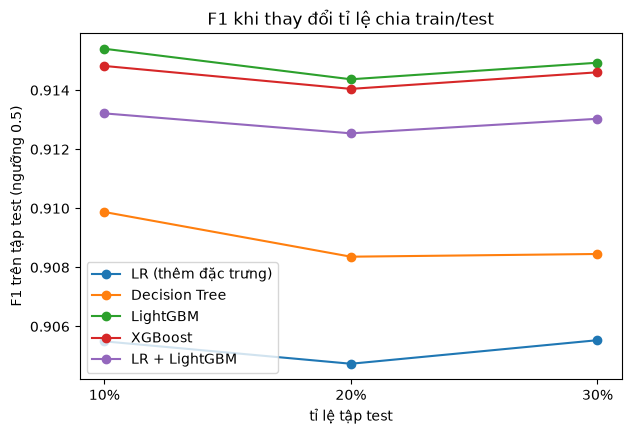

In [70]:
plt.figure(figsize=(7, 4.5))
for name in probs:
    part = ratio_results[ratio_results['model'] == name]
    plt.plot(part['test_size'], part['f1'], marker='o', label=name)
plt.xticks([0.1, 0.2, 0.3], ['10%', '20%', '30%'])
plt.xlabel('tỉ lệ tập test')
plt.ylabel('F1 trên tập test (ngưỡng 0.5)')
plt.title('F1 khi thay đổi tỉ lệ chia train/test')
plt.legend()
plt.show()

### 10.2 So sánh 2 nhóm khách: đi công tác và đi cá nhân

In [71]:
seg_rows = []
for seg in ['Business travel', 'Personal Travel']:
    mask = (X_test['Type of Travel'] == seg).values
    for name in ['LR (thêm đặc trưng)', best_other, 'LR + LightGBM']:
        pred = (test_prob[name] >= best_threshold[name]).astype(int)
        seg_rows.append({'nhóm khách': seg, 'model': name, 'số khách': mask.sum(), 'tỉ lệ hài lòng': y_test[mask].mean(),
                         **get_scores(y_test[mask], pred[mask], test_prob[name][mask])})
segment_results = pd.DataFrame(seg_rows).round(4)
segment_results

,nhóm khách,model,số khách,tỉ lệ hài lòng,accuracy,precision,recall,f1,roc_auc
0,Business travel,LR (thêm đặc trưng),99207,0.5856,0.9109,0.9117,0.9387,0.9250,0.9482
1,Business travel,RealMLP (thêm đặc trưng),99207,0.5856,0.9216,0.9250,0.9427,0.9337,0.9545
2,Business travel,LR + LightGBM,99207,0.5856,0.9197,0.9195,0.9456,0.9324,0.9534
3,Personal Travel,LR (thêm đặc trưng),40720,0.0975,0.9296,0.8107,0.3626,0.5010,0.8200
4,Personal Travel,RealMLP (thêm đặc trưng),40720,0.0975,0.9328,0.9230,0.3384,0.4952,0.8272
5,Personal Travel,LR + LightGBM,40720,0.0975,0.9319,0.8806,0.3492,0.5001,0.8253


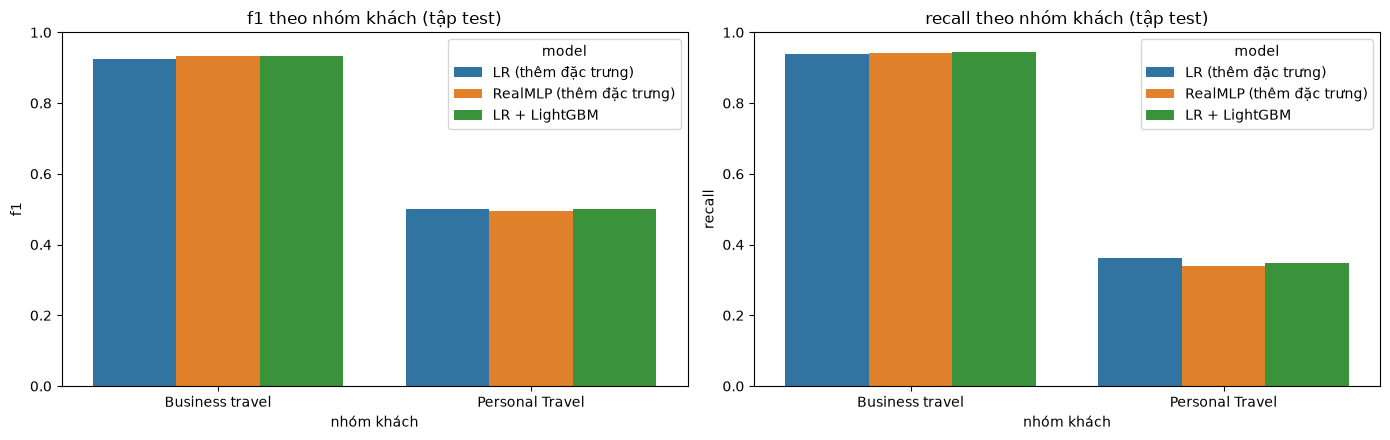

In [72]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for i, metric in enumerate(['f1', 'recall']):
    sns.barplot(data=segment_results, x='nhóm khách', y=metric, hue='model', ax=ax[i])
    ax[i].set_title(f'{metric} theo nhóm khách (tập test)')
    ax[i].set_ylim(0, 1)
plt.tight_layout()
plt.show()

### 10.3 Feature importance (LightGBM, XGBoost)


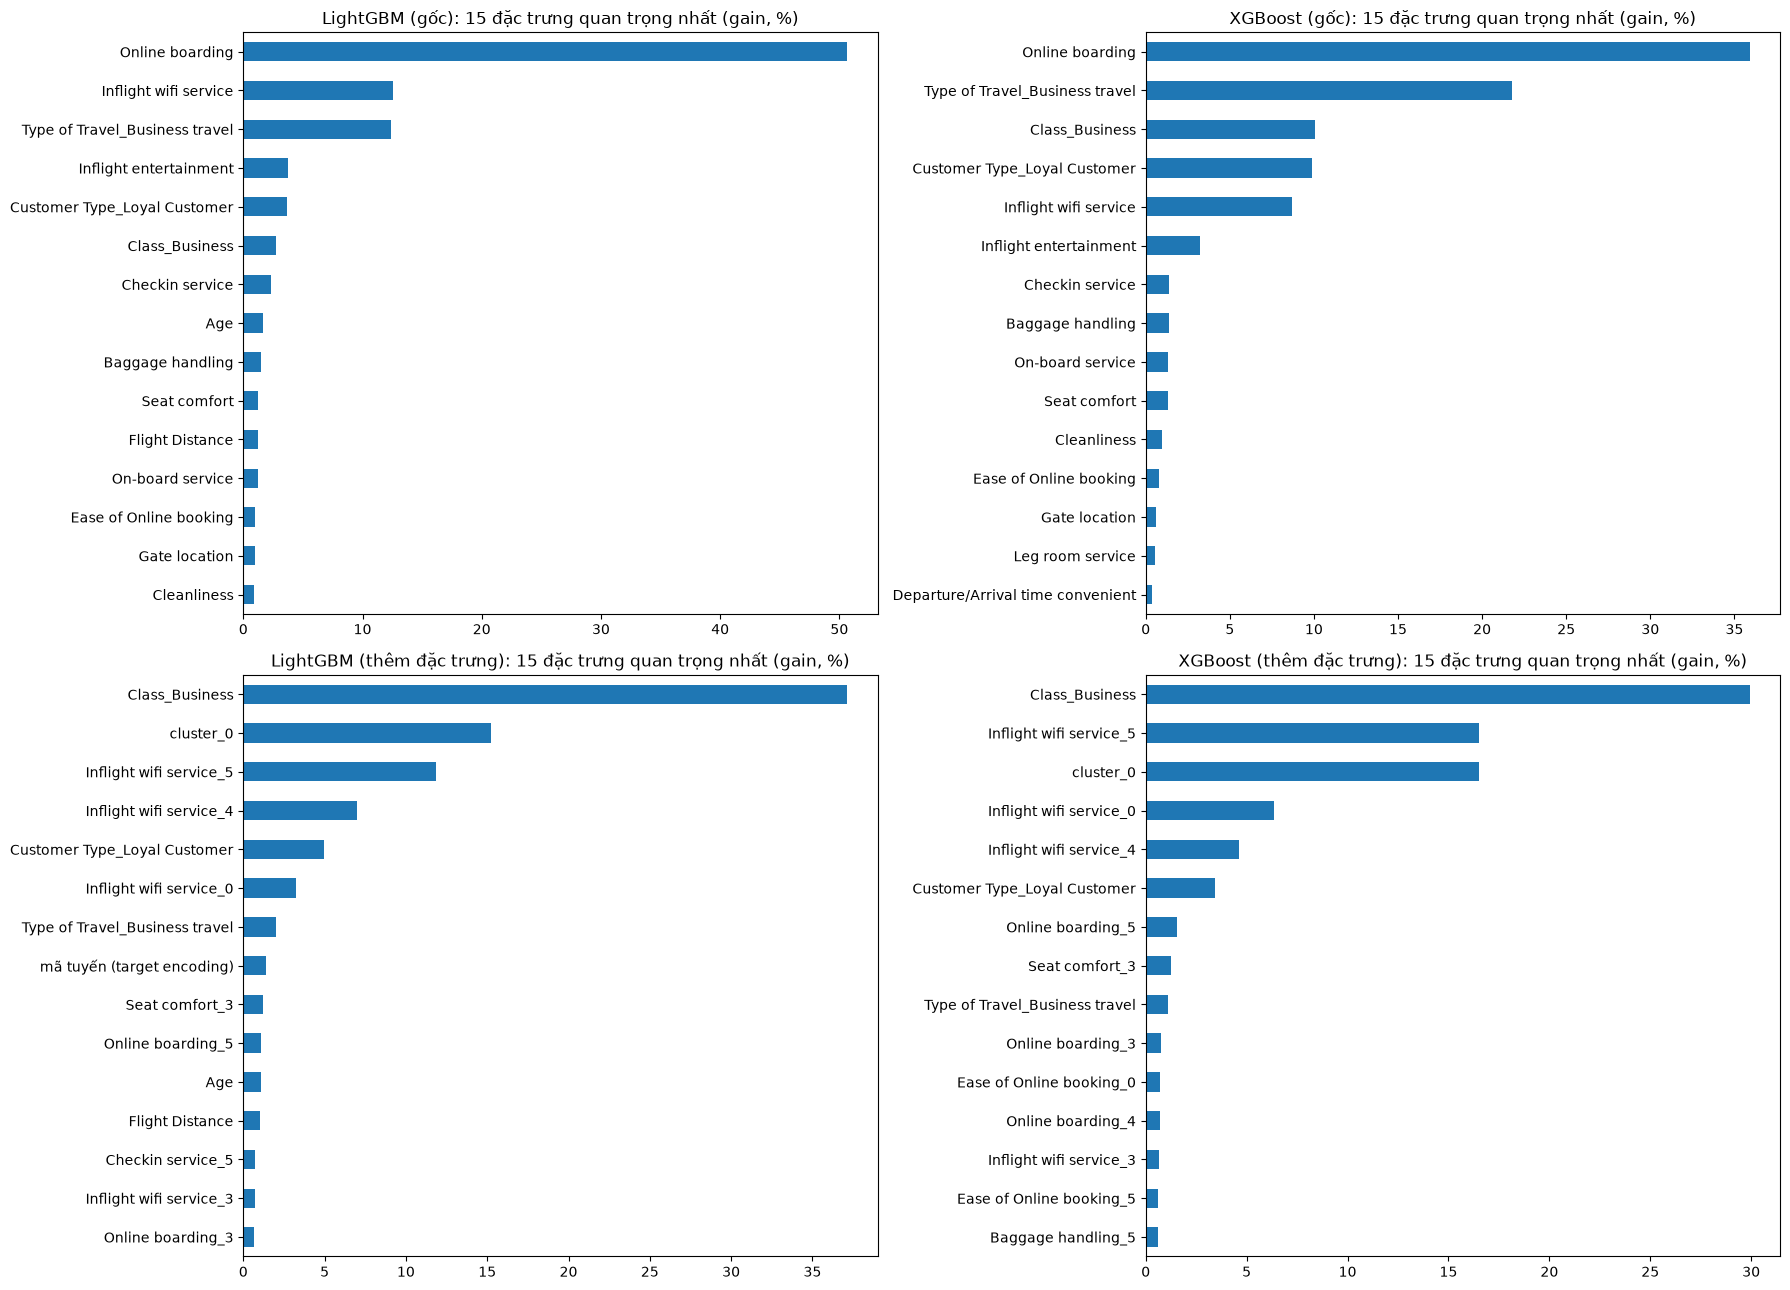

In [73]:
fig, ax = plt.subplots(2, 2, figsize=(18, 13))
ax = ax.flatten()
for i, name in enumerate(['LightGBM (gốc)', 'XGBoost (gốc)', 'LightGBM (thêm đặc trưng)', 'XGBoost (thêm đặc trưng)']):
    pipe = fitted[name]
    names = feature_names(pipe.named_steps['processor'])
    importance = pd.Series(pipe.named_steps['model'].feature_importances_, index=names)
    importance = (importance / importance.sum() * 100).sort_values().tail(15)
    importance.plot(kind='barh', ax=ax[i])
    ax[i].set_title(f'{name}: 15 đặc trưng quan trọng nhất (gain, %)')
plt.tight_layout()
plt.show()

### 10.4 Kết quả tinh chỉnh tham số (GridSearchCV, 5-fold, F1)

In [74]:
tuning_table = pd.DataFrame(tuning_rows)
tuning_table['tăng'] = tuning_table['f1 sau GridSearch'] - tuning_table['f1 mặc định']
tuning_table.round(4)

,model,f1 mặc định,f1 sau GridSearch,tham số tốt nhất,tăng
0,LR (thêm đặc trưng),0.9067,0.9067,{'C': 1},0.0000
1,Decision Tree (gốc),0.8493,0.9101,"{'max_depth': 20, 'min_samples_leaf': 20}",0.0608
2,Decision Tree (thêm đặc trưng),0.8545,0.9103,"{'max_depth': 20, 'min_samples_leaf': 20}",0.0559
3,LightGBM (gốc),0.9145,0.9157,"{'learning_rate': 0.05, 'n_estimators': 500, '...",0.0012
4,LightGBM (thêm đặc trưng),0.9148,0.9162,"{'learning_rate': 0.05, 'n_estimators': 500, '...",0.0014
5,XGBoost (gốc),0.9152,0.9158,"{'learning_rate': 0.1, 'max_depth': 6, 'n_esti...",0.0007
6,XGBoost (thêm đặc trưng),0.9149,0.9159,"{'learning_rate': 0.05, 'max_depth': 8, 'n_est...",0.0009
